In [1]:
import numpy as np
import scipy

import matplotlib.pyplot as plt

import sys
if not '../..' in sys.path:
    sys.path.append('../..')
    sys.path.append('..')

from sklearn.mixture import GaussianMixture
from sklearn.mixture import BayesianGaussianMixture

from analysis import analysis, model

%matplotlib inline

In [2]:
N = 12
covs = [np.eye(64)+np.random.random(size=(64,64))*0.1 for i in range(N)]
means = [np.zeros(shape=(64,)) for i in range(N)]
weights = [1/N for _ in range(N)]

def entropy_gaussian(mean, cov):
    assert cov.shape == (64,64)
    return (64/2)*(1 + np.log(2*np.pi)) + (1/2)*np.log(np.linalg.det(cov))

entropy_gaussian(means[0],covs[0])

91.63063878456592

In [3]:
def multidimensional_gaussian(x, mean, cov):
    return np.exp(-0.5*(x-mean) @ np.linalg.inv(cov) @ (x-mean).T) / np.sqrt(((2*np.pi)**(cov.shape[0]))*np.linalg.det(cov))

- make a multivariate gaussian
- test that, make sure we can evaluate that gaussian at points correctly...
- use that function to compute the pairwise calculation for mixture entropy

In [4]:
m = np.ones(shape=(64,))
c = np.eye(64)*0.1
x = np.ones(shape=(64,))*0.1
my_output = multidimensional_gaussian(x, m, c)

from scipy.stats import multivariate_normal
var = multivariate_normal(mean=m, cov=c)
scipy_output = var.pdf(x)

my_output, scipy_output

(7.746660142100048e-107, 7.746660142098753e-107)

Using Jensen's inequality (to move the logarithm outside of the integral) and the simplifed form of Gaussian convolution:

$$
\begin{align}
H(q) &= - \int_\theta{q(\theta)\log{q(\theta)}d\theta} \\
     &= - \int_\theta{q(\theta)\log{\left\lbrack{\sum_j^N{w_j\,\mathcal{N}\left(\theta\,|\,\mu_i,\Sigma_i\right)}}\right\rbrack}d\theta} \\
     &\geq -\sum_{i}^{N}w_i\log\left\lbrack\sum_{j}^{M}{w_j\int_{\theta}\mathcal{N}\left(\theta\,|\,\mu_i,\Sigma_i\right)\mathcal{N}\left(\theta\,|\,\mu_j,\Sigma_j\right)d\theta}\right\rbrack \\ 
     &= -\sum_{i}^{N}w_i\log\left\lbrack\sum_{j}^{N}{w_j\,\mathcal{N}\left(\mu_i\,|\,\mu_j,\Sigma_i+\Sigma_j\right)}\right\rbrack
\end{align}
$$

In [5]:
def entropy_mixture_lower_bound(means, covs, weights):
    assert len(covs) == len(means)
    assert len(covs) == len(weights)
    # for mean, cov in zip(means, covs):
    #     assert mean.shape == (64,)
    #     assert cov.shape == (64,64)
    entropy = 0
    for i in range(len(covs)):
        inside_sum = 0
        for j in range(len(covs)):
            inside_sum += weights[j]*multivariate_normal(mean=means[j], cov=(covs[i] + covs[j])).pdf(means[i])
        entropy += weights[i]*np.log(inside_sum)
    return -1*entropy

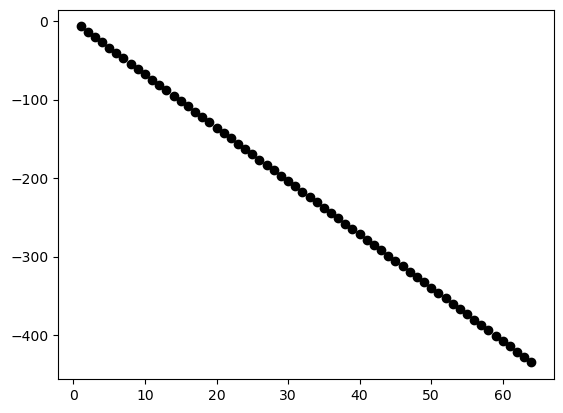

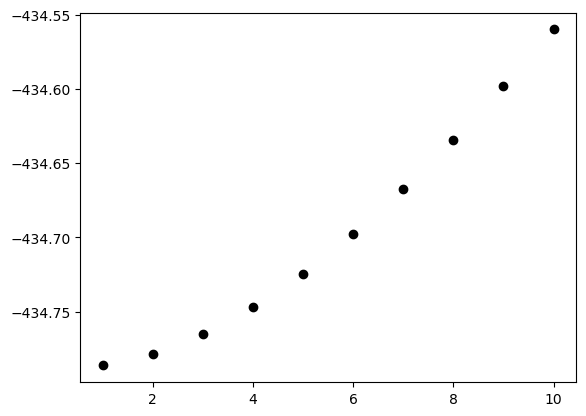

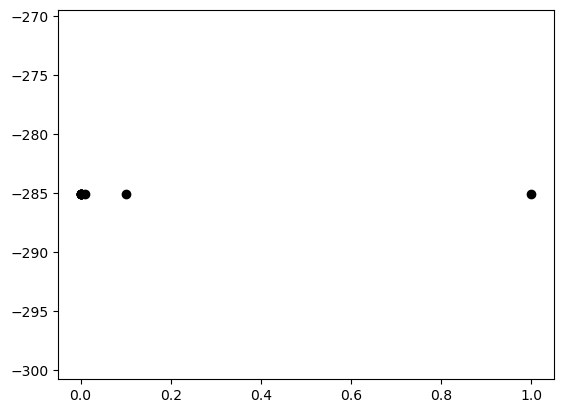

In [17]:
# dimensions
N = 1
dists = []
for d in range(1, 65):
    means = [np.zeros(shape=(d,))+(i*0.00001) for i in range(N)]
    covs = [np.eye(d)*0.0000001 for _ in range(N)]
    weights = [1/N for _ in range(N)]
    dists += [entropy_mixture_lower_bound(means, covs, weights)]

plt.figure()
plt.plot(range(1,65),dists,"ko")

# components
d = 64
dists = []
for N in range(1, 11):
    means = [np.zeros(shape=(d,))+(i*0.00001) for i in range(N)]
    covs = [np.eye(d)*0.0000001 for _ in range(N)]
    weights = [1/N for _ in range(N)]
    dists += [entropy_mixture_lower_bound(means, covs, weights)]

plt.figure()
plt.plot(range(1,11),dists,"ko")

# covariance magnitude
d = 64
N = 10
dists = []
for e in range(0, 10):
    eps = 1 * 10**e
    means = [np.zeros(shape=(d,))+(i*eps) for i in range(N)]
    covs = [np.eye(d)*0.00001 for _ in range(N)]
    weights = [1/N for _ in range(N)]
    dists += [entropy_mixture_lower_bound(means, covs, weights)]

plt.figure()
plt.plot([1 * 10**-e for e in range(0,10)], dists, "ko")

In [7]:
# x = np.linspace(-3,3,100)
# for D in dists:
#     plt.figure()
#     plt.plot(x, D.pdf(x), '--')

In [8]:
def true_gaussian_entropy(cov):
    # https://gregorygundersen.com/blog/2020/09/01/gaussian-entropy/
    assert cov.shape == (64,64)
    # (D/2)*(1 + log(2pi)) + (1/2)*log(det(C))
    return 32*(1 + np.log(2*np.pi)) + 0.5*np.log(np.linalg.det(cov))
    # return np.log(np.linalg.det(cov)**(1/64))


In [10]:
import sys
if not '../..' in sys.path:
    sys.path.append('../..')
    sys.path.append('..')
from analysis import collection, analysis, emg, plot, model
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib import patches, lines
from pathlib import Path
import numpy as np
import seaborn as sns
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from joblib import dump, load
from analysis.offsets import offsets

mpl.rcParams.update(mpl.rcParamsDefault)
mpl.rcParams.update({'axes.labelsize': 16})
mpl.rcParams.update({'figure.figsize': (16*0.8,9*0.8)})
mpl.rcParams.update({'axes.facecolor': "white"})
mpl.rcParams.update({'lines.marker': "+"})
mpl.rcParams.update({'lines.linestyle': ""})
mpl.rcParams.update({"axes.spines.left":   True})
mpl.rcParams.update({"axes.spines.bottom": True})
mpl.rcParams.update({"axes.spines.top":    False})
mpl.rcParams.update({"axes.spines.right":  False})

image_path = Path("/Users/spencer/phd/phd/images/more_results/gmms/")

%matplotlib inline

In [11]:
subjects = analysis.load_subjects()

In [12]:
import pandas as pd
trajectory_df = pd.read_pickle("../trajectory_dataframe.pkl")
mean_rewards = 1 / trajectory_df.groupby(level=['subject']).mean()["reward"]

In [13]:
model_entropies = []
for subject_idx in range(len(subjects)):
    log_models = model.load_log_trial_models(subject_idx)
    model_entropies.append([entropy_mixture_lower_bound(m.means_,m.covariances_,m.weights_) for m in log_models])

calibration_entropies = []
for subject_idx in range(len(subjects)):
    log_calibration_model = model.load_log_calibration_models(subject_idx)[0]
    calibration_entropies.append(entropy_mixture_lower_bound(log_calibration_model.means_,log_calibration_model.covariances_,log_calibration_model.weights_))

movement_entropies = []
for subject_idx in range(len(subjects)):
    log_movement_model = model.load_log_movement_models(subject_idx)[0]
    movement_entropies.append(entropy_mixture_lower_bound(log_movement_model.means_,log_movement_model.covariances_,log_movement_model.weights_))

### higher entropy -- more equiprobable outcomes || lower entropy -- less equiprobable outcomes

goes to negative infinity -- meaning delta function, complete information about the outcome!

Text(0.5, 0, 'Mean Reward')

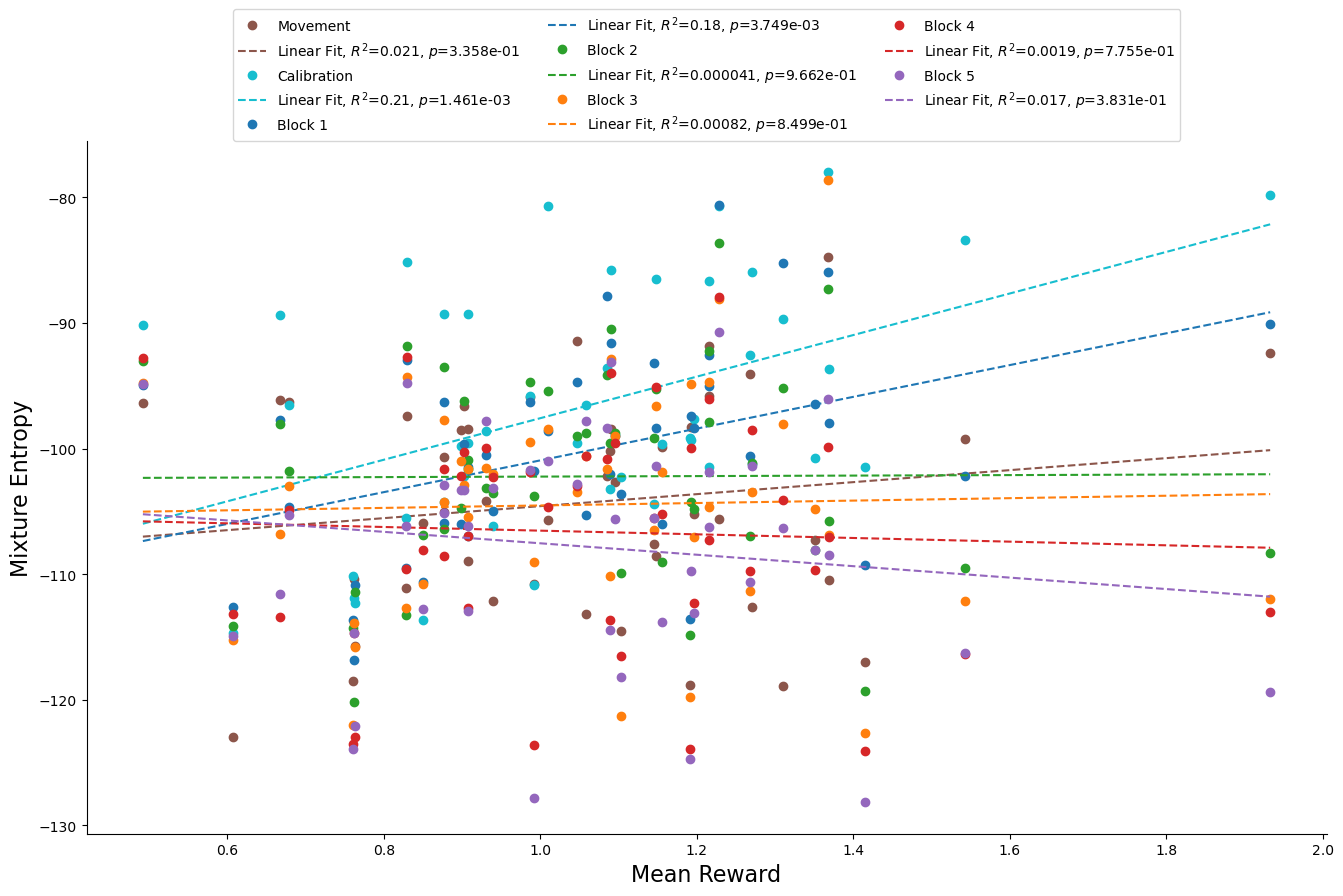

In [19]:
entropy_fig = plt.figure(figsize=(16,9))

plt.plot(mean_rewards,movement_entropies,"o",color="tab:brown",label="Movement")
res = analysis.linear_fit(mean_rewards,movement_entropies)
x = np.linspace(min(mean_rewards),max(mean_rewards),100,endpoint=True)
plot.plot_linear_fit(x,res,plt.gca(),color="tab:brown")

plt.plot(mean_rewards,calibration_entropies,"o",color="tab:cyan",label="Calibration")
res = analysis.linear_fit(mean_rewards,calibration_entropies)
x = np.linspace(min(mean_rewards),max(mean_rewards),100,endpoint=True)
plot.plot_linear_fit(x,res,plt.gca(),color="tab:cyan")

c = ["tab:blue","tab:green","tab:orange","tab:red","tab:purple"]
for i in range(5):
    me = [m[i] for m in model_entropies]
    plt.plot(mean_rewards,me,"o",color=c[i],label=f"Block {i+1}")
    res = analysis.linear_fit(mean_rewards,me)
    x = np.linspace(mean_rewards.min(),mean_rewards.max(),100,endpoint=True)
    plot.plot_linear_fit(x,res,plt.gca(),color=c[i])

plt.legend(loc='upper center', bbox_to_anchor=(0.5, 1.2),fancybox=True, ncol=3)
plt.ylabel("Mixture Entropy")
plt.xlabel("Mean Reward")

In [20]:
plot.save_figure(entropy_fig, "entropy_gmms", image_path)

Figure saved to /Users/spencer/phd/phd/images/more_results/gmms/entropy_gmms.pdf


(46, 7)


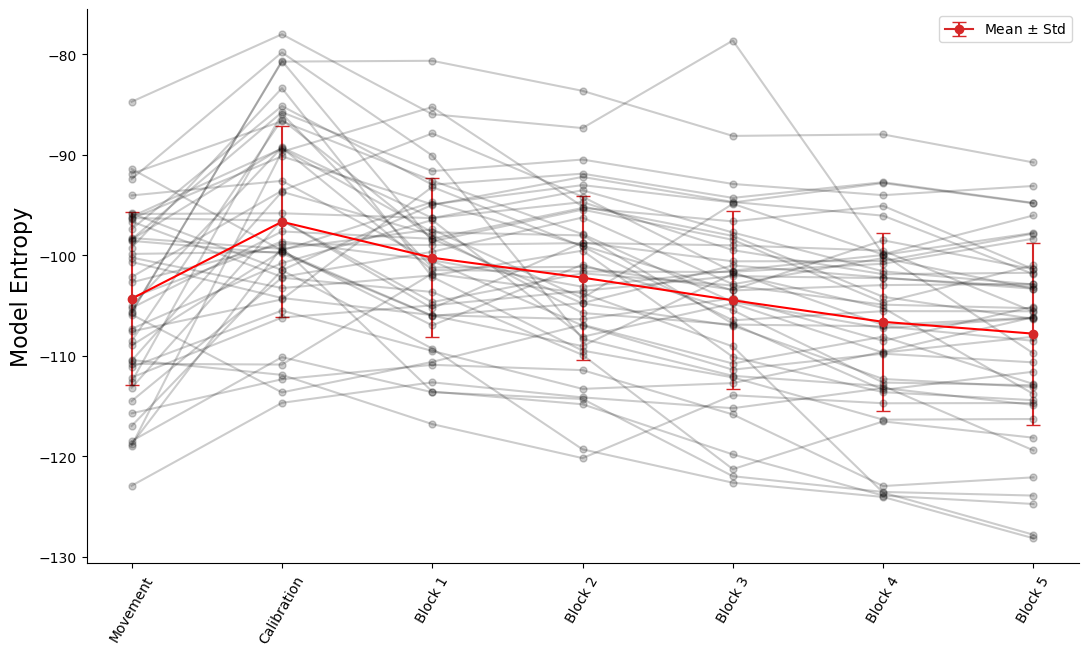

In [21]:
fig = plt.figure()
# plt.plot(0*np.ones_like(movement_entropies), movement_entropies,"k",alpha=0.3,label="Subjects")
print(np.hstack([np.array(movement_entropies).reshape(-1,1),np.array(calibration_entropies).reshape(-1,1),np.array(model_entropies)]).shape)
plt.errorbar(x=0, y=np.mean(movement_entropies), yerr=np.std(movement_entropies), capsize=5, color="tab:red",linestyle="-",marker="o")
# plt.plot(np.ones_like(calibration_entropies), calibration_entropies,"k",alpha=0.3)
plt.errorbar(x=1, y=np.mean(calibration_entropies), yerr=np.std(calibration_entropies), capsize=5, color="tab:red",linestyle="-",marker="o",label="Mean $\pm$ Std")
for mi, pi in enumerate(range(2,7)):
    me = [m[mi] for m in model_entropies]
    # plt.plot(pi*np.ones_like(me),me,"ko",alpha=0.3)
    plt.errorbar(x=pi, y=np.mean(me),yerr=np.std(me),capsize=5,color="tab:red",linestyle="-",marker="o")
plt.plot(np.hstack([np.array(movement_entropies).reshape(-1,1),np.array(calibration_entropies).reshape(-1,1),np.array(model_entropies)]).T,"k-",marker='o',alpha=0.2,markersize=5)
plt.plot(range(7),np.concatenate([np.mean(movement_entropies).reshape(1,1),np.mean(calibration_entropies).reshape(1,1),np.mean(np.array(model_entropies),axis=0).reshape(5,1)]),"r-")
plt.legend()
plt.ylabel("Model Entropy")
xlabels = ["Movement", "Calibration", *[f"Block {i+1}" for i in range(5)]]
_ = plt.xticks(range(7),xlabels,rotation=60)

In [ ]:
# fig = plt.figure()
# plt.plot(0*np.ones_like(movement_entropies), movement_entropies,"k",alpha=0.3,label="Subjects")
# plt.errorbar(x=0, y=np.mean(movement_entropies), yerr=np.std(movement_entropies), capsize=5, color="r",linestyle="-",marker="o")
# plt.plot(np.ones_like(calibration_entropies), calibration_entropies,"k",alpha=0.3)
# plt.errorbar(x=1, y=np.mean(calibration_entropies), yerr=np.std(calibration_entropies), capsize=5, color="r",linestyle="-",marker="o",label="Mean $\pm$ Std")
# for mi, pi in enumerate(range(2,7)):
#     me = [m[mi] for m in model_entropies]
#     plt.plot(pi*np.ones_like(me),me,"ko",alpha=0.3)
#     plt.errorbar(x=pi, y=np.mean(me),yerr=np.std(me),capsize=5,color="r",linestyle="-",marker="o")
# plt.plot(range(7),np.concatenate([np.mean(movement_entropies).reshape(1,1),np.mean(calibration_entropies).reshape(1,1),np.mean(np.array(model_entropies),axis=0).reshape(5,1)]),"r-")
# plt.legend()
# plt.ylabel("Model Entropy")
# xlabels = ["Movement", "Calibration", *[f"Block {i+1}" for i in range(5)]]
# _ = plt.xticks(range(7),xlabels,rotation=60)

In [22]:
plot.save_figure(fig,"entropy_over_models",image_path)

Figure saved to /Users/spencer/phd/phd/images/more_results/gmms/entropy_over_models.pdf


In [16]:
entropy_stack = np.concatenate([np.array(movement_entropies).reshape(1,-1), np.array(calibration_entropies).reshape(1,-1), np.array(model_entropies).T])
entropy_stack.shape

(7, 46)

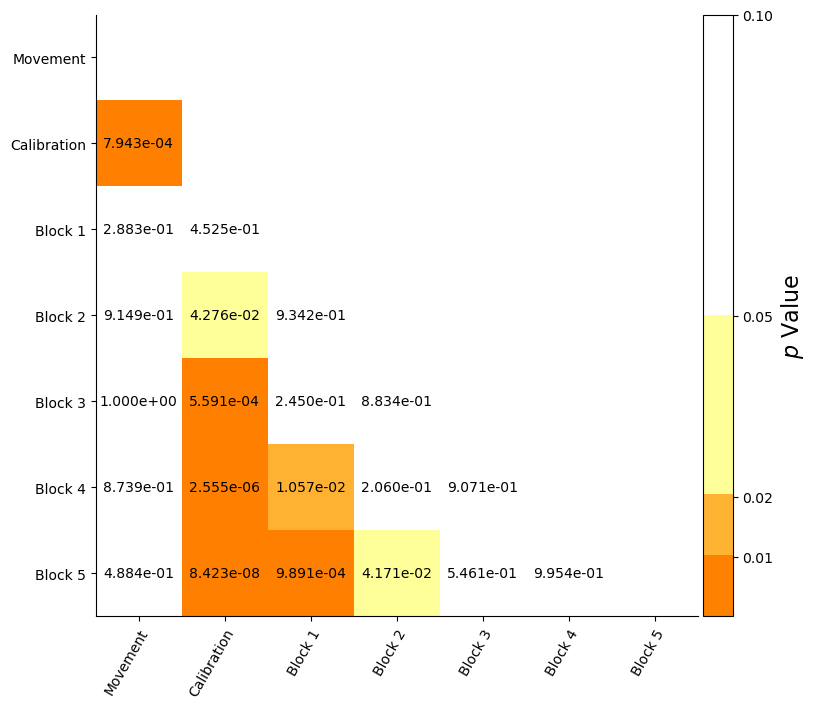

In [23]:
from scipy.stats import tukey_hsd
result = tukey_hsd(*(np.array(entropy_stack)))
entropy_pvalue_fig, _ = plot.annotated_heatmap(result.pvalue,xlabels,xlabels)

In [24]:
plot.save_figure(entropy_pvalue_fig,"model_entropy_pvalues",image_path,format="png")

Figure saved to /Users/spencer/phd/phd/images/more_results/gmms/model_entropy_pvalues.png


0.0003741289333080754


Text(0.5, 0, 'Mean Rewards')

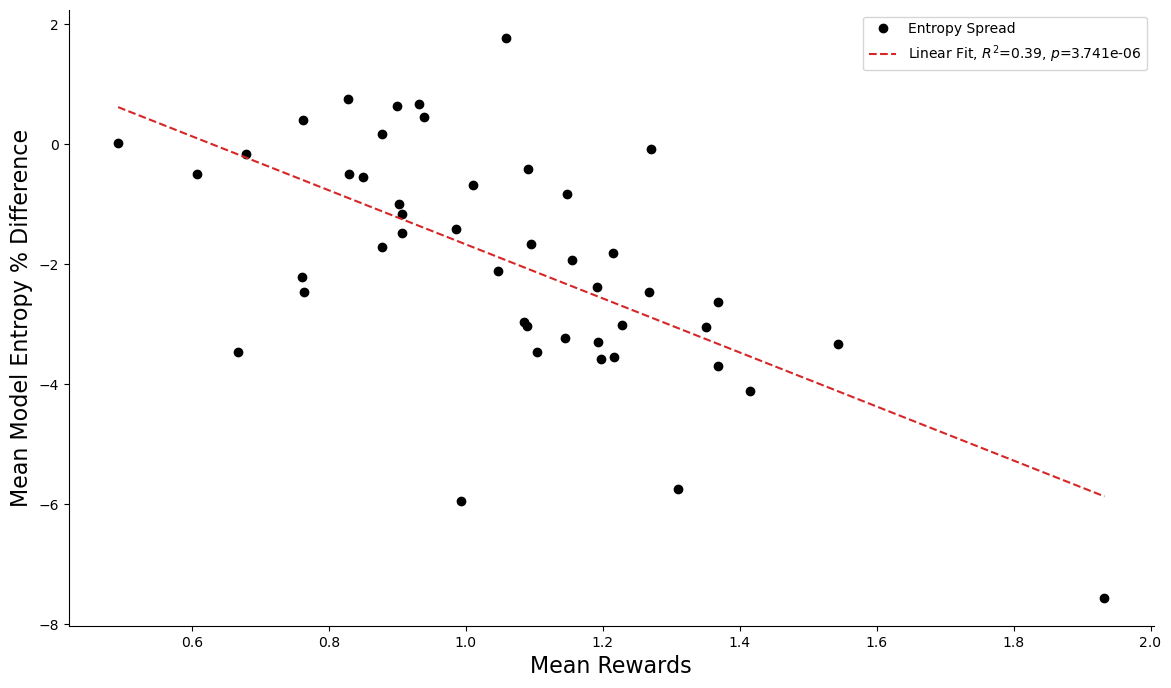

In [25]:
# fig, axes = plt.subplots(2,1,figsize=(13,15))
entropy_diff_fig, ax = plt.subplots(1,1,figsize=(14,8))
axes = [None, ax]
# me = [np.abs(m[0]-m[-1]) for i, m in enumerate(model_entropies) if not i in []]
# xr = [mr for i, mr in enumerate(mean_rewards) if not i in []]
# axes[0].plot(xr,me,"o",color="k",label=f"Entropy Difference")
# res = analysis.linear_fit(xr,me)
# x = np.linspace(mean_rewards.min(),mean_rewards.max(),100,endpoint=True)
# plot.plot_linear_fit(x,res,axes[0])
# axes[0].legend(loc=4)
# axes[0].set_xlabel("Mean Reward")
# axes[0].set_ylabel("Trial Entropy Spread")

entropy_mean_diffs = []
stop_idx = []
for i, e in enumerate(model_entropies):
    if not i in stop_idx:
        e = np.array(e)
        # percent difference -- (x2 - x1)/x1
        entropy_mean_diffs.append(100*np.mean([(e[i+1]-e[i])/np.abs(e[i]) for i in range(4)]))
        # entropy_mean_diffs.append(np.mean([(e[i+1]-e[i])/np.abs(e[i]) for i in range(e.shape[0]-1)]))
rewards = np.array([m for i, m in enumerate(mean_rewards) if not i in stop_idx])
axes[1].plot(rewards, entropy_mean_diffs, 'ko',label=f"Entropy Spread")
res = analysis.linear_fit(rewards,entropy_mean_diffs)
x = np.linspace(rewards.min(),rewards.max(),100,endpoint=True)
plot.plot_linear_fit(x,res,axes[1])
axes[1].legend()
print(res.pvalue*100)
axes[1].set_ylabel("Mean Model Entropy % Difference")
axes[1].set_xlabel("Mean Rewards")

In [26]:
plot.save_figure(entropy_diff_fig, "entropy_diffs", image_path)

Figure saved to /Users/spencer/phd/phd/images/more_results/gmms/entropy_diffs.pdf
